# Exploratory Data Analysis of Concrete Compressive Strength

COS40007 Artificial Intelligence Engineering | Portfolio Assessment 1

Student Name: Nguyen Van Tuan Kiet

Student ID: 104772099

Class Number: COS40007

Date: 04 October 2026

Dataset: [Concrete Compressive Strength Data Set](https://www.kaggle.com/datasets/elikplim/concrete-compressive-strength-data-set) (supplied concrete_data.csv)

GitHub Repository: https://github.com/odmiefnf/COS40007

## Generative AI declaration
OpenAI Codex assisted with dataset research, analysis design, code generation and debugging, execution checks, visualisations, interpretation drafts, report writing and formatting. The numerical results were computed from the downloaded CSV. This is an AI-assisted draft; student verification and revision of the code, interpretations and conclusions are still required. No claim is made that all code and interpretations were independently authored by the student. The assignment lists narrower permitted GenAI uses, so acceptance of this broader assistance must be checked with the tutor before submission.

## Acknowledgement of Country
I acknowledge the Traditional Owners of the lands on which Swinburne operates in Australia,
and pay respect to Elders past and present. I recognise their continuing connection to land,
waters and communities.

## Purpose and scope
This analysis examines how concrete mix quantities and test age relate to measured compressive
strength. It prepares the data for future machine learning, identifies quality concerns and
explains findings in a materials engineering context. Model training is outside this task.
The continuous response is retained for engineering interpretation; a three-class version is
prepared to meet the numerical-target discretisation requirement.

## 1 Dataset overview

The selected Kaggle dataset is Concrete Compressive Strength Data Set, uploaded by Ahiale
Darlington (elikplim). It is a mirror of I-Cheng Yeh's UCI dataset [1, 2]. Each observation
contains seven ingredient quantities, concrete age and laboratory-measured strength.
The original table has 1,030 observations, eight numerical predictors and one target.
The ingredients are measured in kg/m3, age in days and strength in MPa.

Kaggle: https://www.kaggle.com/datasets/elikplim/concrete-compressive-strength-data-set

Original source: https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength

The engineering application is preliminary mix screening and strength estimation. No model
from this analysis is approved for structural acceptance. The raw response defines regression;
the derived ordered strength bands define a three-class classification alternative.

### Task 1 Loading and initial exploration
The source CSV is bundled locally. Column-name whitespace is normalised without changing
measurements. Full numerical precision is used for computations; tables are rounded for display.

In [1]:
from pathlib import Path
import hashlib
import io
import json
import base64
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Run this notebook from the portfolio1 folder; no network is required.
ROOT = Path.cwd()
DATA_PATH = ROOT / 'data' / 'concrete' / 'concrete_data.csv'
# The submission notebook includes the unchanged CSV in its metadata.
if DATA_PATH.exists():
    source_bytes = DATA_PATH.read_bytes()
else:
    notebook_file = next(ROOT.glob('Portfolio_Assessment_1*.ipynb'))
    metadata = json.loads(notebook_file.read_text(encoding='utf-8'))['metadata']
    source_bytes = base64.b64decode(metadata['source_csv_base64'])
OUTPUT = ROOT / 'output'
OUTPUT.mkdir(exist_ok=True)
raw = pd.read_csv(io.BytesIO(source_bytes))
raw.columns = raw.columns.str.strip()
TARGET = 'concrete_compressive_strength'
PREDICTORS = [c for c in raw.columns if c != TARGET]
LABELS = {c: c.replace('_', ' ').title() for c in raw.columns}
UNITS = {c: 'kg/m3' for c in PREDICTORS}
UNITS['age'] = 'days'
UNITS[TARGET] = 'MPa'
sns.set_theme(style='whitegrid', font_scale=0.9)
pd.set_option('display.max_columns', None)
def print_table(frame, columns_per_block=4):
    # Keep evidence readable in both the notebook and an A4 PDF.
    for start in range(0, len(frame.columns), columns_per_block):
        print(frame.iloc[:, start:start + columns_per_block].to_string())
        print()
print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| numpy:', np.__version__)
print('CSV SHA256:', hashlib.sha256(source_bytes).hexdigest())
print('Shape (rows, columns):', raw.shape)

Python: 3.12.14
pandas: 3.0.1 | numpy: 2.3.5
CSV SHA256: 1903285682ab24ebc5c1d4f79f8b9a389d01c23d528d3b64b52174847315c945
Shape (rows, columns): (1030, 9)


In [2]:
print('FIRST FIVE OBSERVATIONS (transposed for readability)')
print(raw.head().T.to_string())
print('\nCOLUMN DATA TYPES')
print(raw.dtypes.to_string())
print('\nINITIAL MISSING VALUE COUNTS')
print(raw.isna().sum().to_string())
print('\nRAW NUMERICAL SUMMARY')
print_table(raw.describe().T.round(3))

FIRST FIVE OBSERVATIONS (transposed for readability)
                                     0        1       2       3      4
cement                          540.00   540.00  332.50  332.50  198.6
blast_furnace_slag                0.00     0.00  142.50  142.50  132.4
fly_ash                           0.00     0.00    0.00    0.00    0.0
water                           162.00   162.00  228.00  228.00  192.0
superplasticizer                  2.50     2.50    0.00    0.00    0.0
coarse_aggregate               1040.00  1055.00  932.00  932.00  978.4
fine_aggregate                  676.00   676.00  594.00  594.00  825.5
age                              28.00    28.00  270.00  365.00  360.0
concrete_compressive_strength    79.99    61.89   40.27   41.05   44.3

COLUMN DATA TYPES
cement                           float64
blast_furnace_slag               float64
fly_ash                          float64
water                            float64
superplasticizer                 float64
coarse_aggreg

The file contains numeric measurements in all nine columns. Stored integer age is a
discrete time variable; ingredient and response columns are floating-point values. Zero slag,
fly ash or superplasticizer represents an absent ingredient, not missing data. The CSV header
for fine aggregate contained trailing whitespace; stripping headers prevents indexing errors.

## 2 Data quality assessment
### Task 2 Missing values, duplicates and outliers
Missingness is checked across the entire raw table. The heatmap displays all 1,030 rows, rather
than a sample. Exact duplicates are identified using all nine measurements. Removing them is
an explicit conservative analysis choice, not proof that repeated laboratory tests are errors.
The original CSV is preserved and duplicate sensitivity is reported below.

                               missing_count  missing_percent
cement                                     0              0.0
blast_furnace_slag                         0              0.0
fly_ash                                    0              0.0
water                                      0              0.0
superplasticizer                           0              0.0
coarse_aggregate                           0              0.0
fine_aggregate                             0              0.0
age                                        0              0.0
concrete_compressive_strength              0              0.0


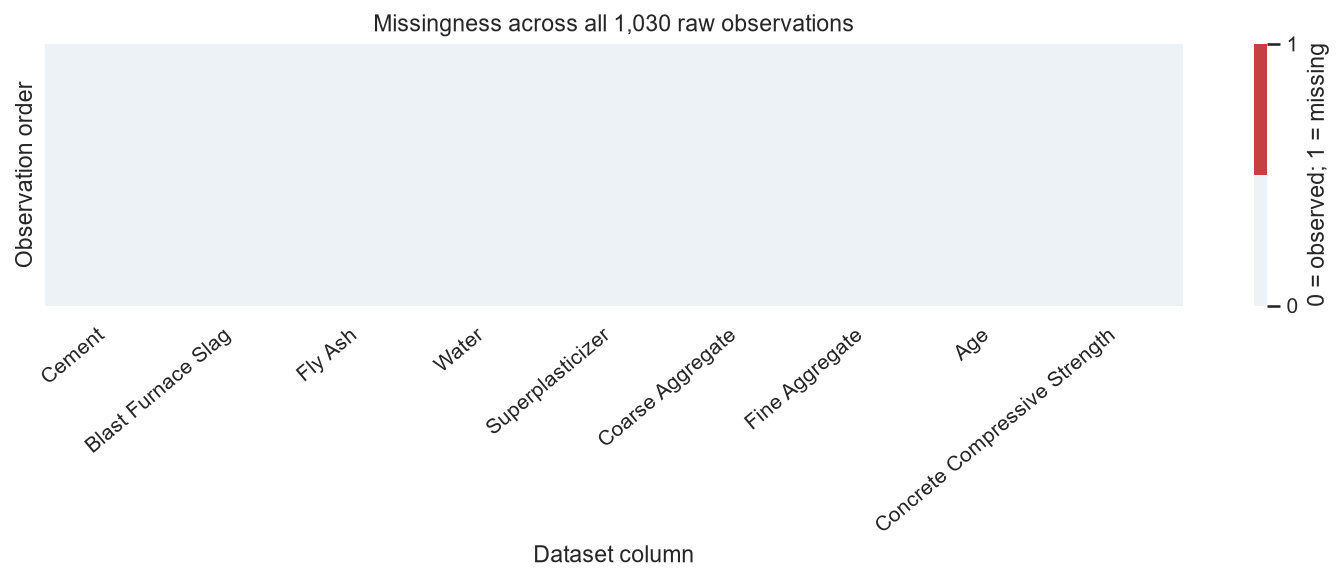

In [3]:
missing = pd.DataFrame({
    'missing_count': raw.isna().sum(),
    'missing_percent': raw.isna().mean() * 100
})
print(missing.round(2).to_string())
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(raw.isna(), cmap=['#edf2f7', '#c54040'],
            vmin=0, vmax=1, yticklabels=False, ax=ax,
            cbar_kws={'ticks': [0, 1], 'label': '0 = observed; 1 = missing'})
ax.set(title='Missingness across all 1,030 raw observations',
       xlabel='Dataset column', ylabel='Observation order')
ax.set_xticklabels([LABELS[c] for c in raw.columns], rotation=40, ha='right')
fig.tight_layout()
fig.savefig(OUTPUT / '01_missingness.png', dpi=180)
plt.show()

In [4]:
duplicate_count = int(raw.duplicated().sum())
duplicate_examples = raw.loc[raw.duplicated(keep=False)].head(6)
print('Exact duplicate rows beyond first occurrences:', duplicate_count)
print('Example duplicate-group rows (transposed):')
print(duplicate_examples.T.to_string())
# Drop only identical full rows; retain different outcomes for the same inputs.
clean = raw.drop_duplicates().copy()
print('After deduplication:', clean.shape)
print('Repeated predictor vectors beyond first occurrence:',
      int(clean.duplicated(subset=PREDICTORS).sum()))
print('Data types after cleaning:')
print(clean.dtypes.to_string())
invalid = pd.Series({
    'nonfinite_numeric_cells': int((~np.isfinite(clean)).sum().sum()),
    'negative_ingredient_cells': int((clean[PREDICTORS[:-1]] < 0).sum().sum()),
    'nonpositive_age_rows': int((clean['age'] <= 0).sum()),
    'noninteger_age_rows': int((clean['age'] % 1 != 0).sum()),
    'nonpositive_strength_rows': int((clean[TARGET] <= 0).sum())
})
print('Basic domain checks:')
print(invalid.to_string())

Exact duplicate rows beyond first occurrences: 25
Example duplicate-group rows (transposed):
                                  72     77     80     83     86     88
cement                         425.0  425.0  425.0  362.6  362.6  362.6
blast_furnace_slag             106.3  106.3  106.3  189.0  189.0  189.0
fly_ash                          0.0    0.0    0.0    0.0    0.0    0.0
water                          153.5  153.5  153.5  164.9  164.9  164.9
superplasticizer                16.5   16.5   16.5   11.6   11.6   11.6
coarse_aggregate               852.1  852.1  852.1  944.7  944.7  944.7
fine_aggregate                 887.1  887.1  887.1  755.8  755.8  755.8
age                              3.0    3.0    3.0    3.0    3.0    3.0
concrete_compressive_strength   33.4   33.4   33.4   35.3   35.3   35.3
After deduplication: (1005, 9)
Repeated predictor vectors beyond first occurrence: 13
Data types after cleaning:
cement                           float64
blast_furnace_slag               

                               lower_fence  upper_fence  flagged_count  flagged_percent
cement                             -46.750      586.450              0            0.000
blast_furnace_slag                -213.750      356.250              2            0.199
fly_ash                           -177.450      295.750              0            0.000
water                              127.150      232.350             15            1.493
superplasticizer                   -15.000       25.000             10            0.995
coarse_aggregate                   783.500     1179.500              0            0.000
fine_aggregate                     577.450      969.050              5            0.498
age                                -66.500      129.500             59            5.871
concrete_compressive_strength       -8.505       76.895              8            0.796
Rows with at least one flag: 94


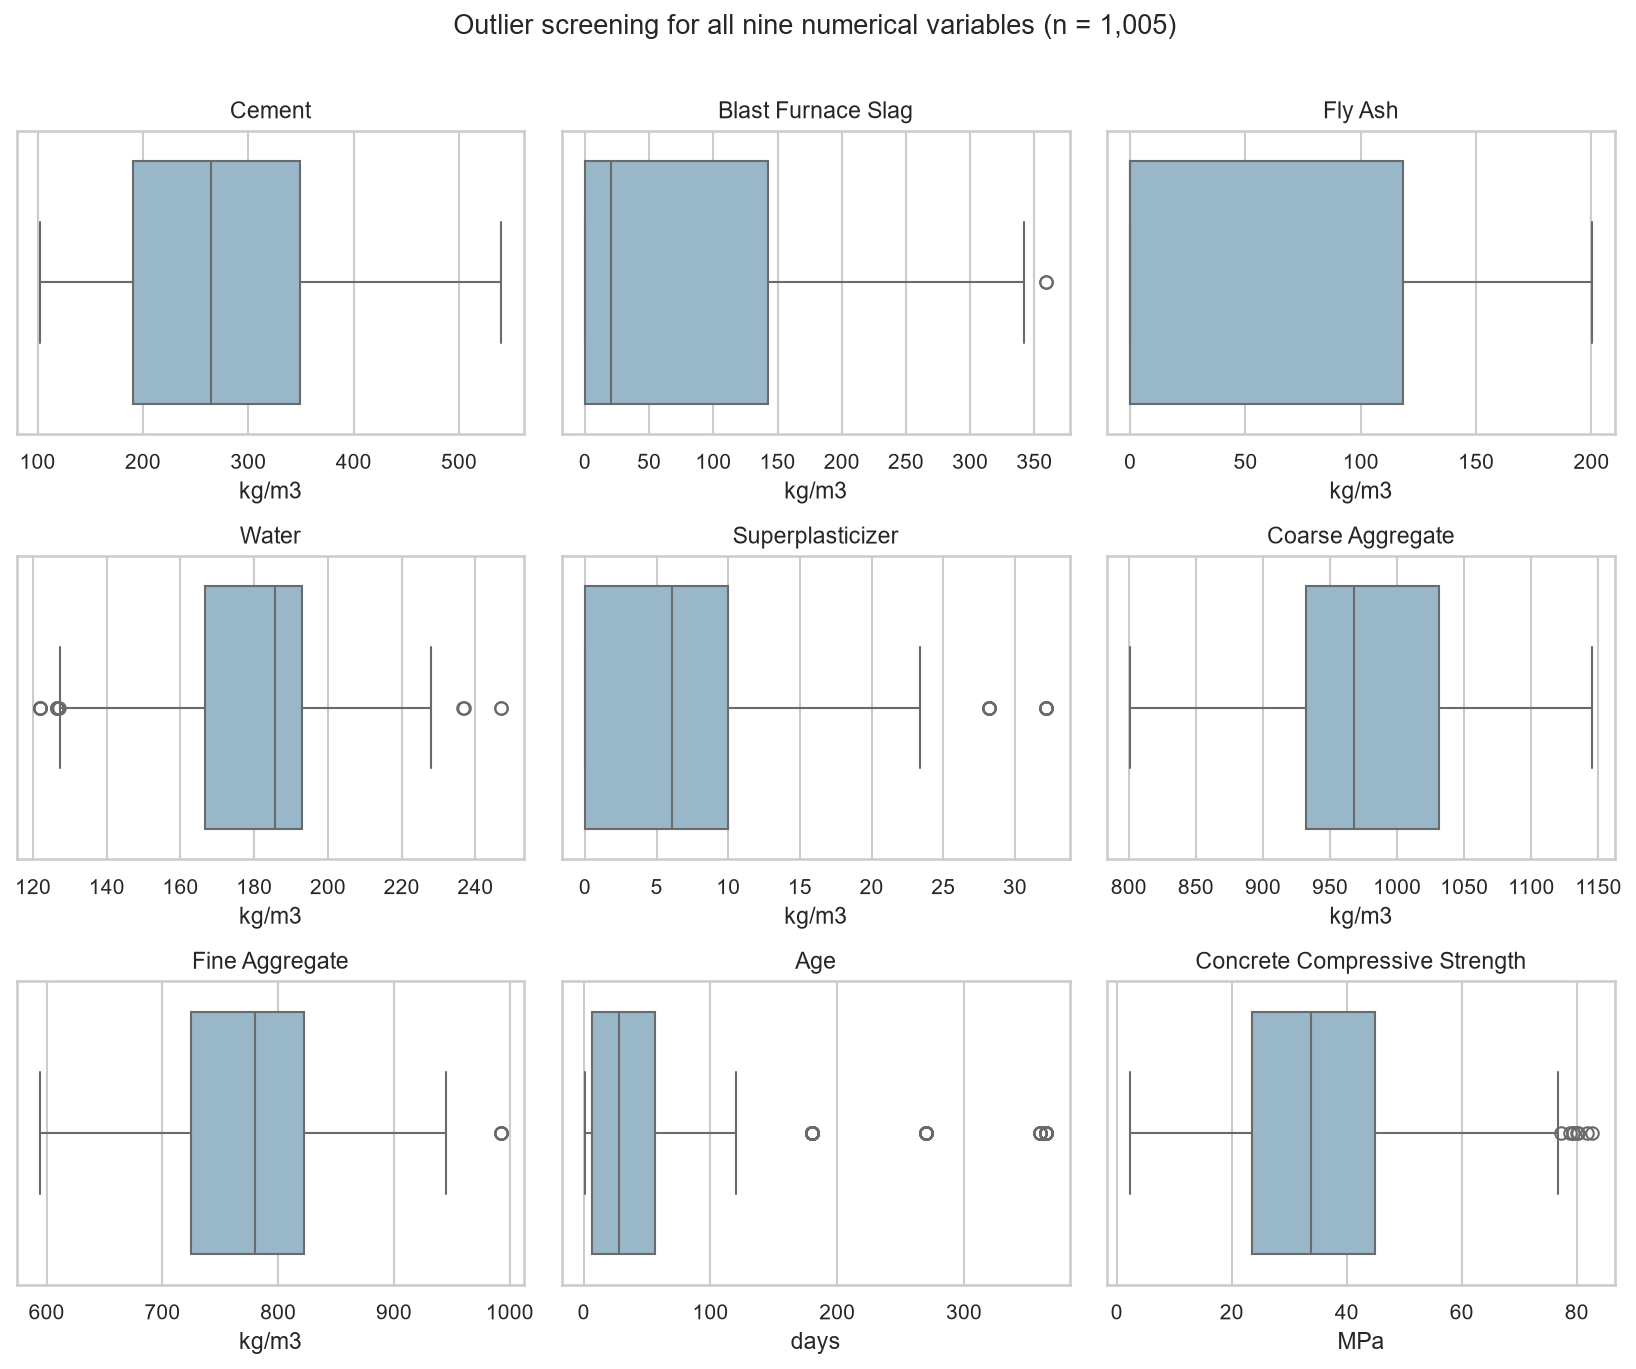

In [5]:
# Tukey fences are screening rules, not automatic deletion criteria.
q1 = clean.quantile(0.25)
q3 = clean.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
outlier_flags = clean.lt(low) | clean.gt(high)
outlier_table = pd.DataFrame({
    'lower_fence': low, 'upper_fence': high,
    'flagged_count': outlier_flags.sum(),
    'flagged_percent': outlier_flags.mean() * 100
})
print(outlier_table.round(3).to_string())
print('Rows with at least one flag:', int(outlier_flags.any(axis=1).sum()))
fig, axes = plt.subplots(3, 3, figsize=(11, 9))
for ax, col in zip(axes.flat, clean.columns):
    sns.boxplot(x=clean[col], color='#90b9d1', ax=ax)
    ax.set(title=LABELS[col], xlabel=UNITS[col])
fig.suptitle('Outlier screening for all nine numerical variables (n = 1,005)', y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT / '02_boxplots.png', dpi=180, bbox_inches='tight')
plt.show()

In [6]:
# Check how deduplication changes strength and target correlations.
sensitivity = pd.DataFrame({
    'raw_Pearson_r': raw.corr()[TARGET].drop(TARGET),
    'deduplicated_Pearson_r': clean.corr()[TARGET].drop(TARGET)
})
sensitivity['change'] = (sensitivity['deduplicated_Pearson_r']
                         - sensitivity['raw_Pearson_r'])
print(sensitivity.round(4).to_string())
print('Raw mean strength:', round(raw[TARGET].mean(), 4))
print('Deduplicated mean strength:', round(clean[TARGET].mean(), 4))

                    raw_Pearson_r  deduplicated_Pearson_r  change
cement                     0.4978                  0.4883 -0.0095
blast_furnace_slag         0.1348                  0.1034 -0.0315
fly_ash                   -0.1058                 -0.0806  0.0251
water                     -0.2896                 -0.2696  0.0200
superplasticizer           0.3661                  0.3442 -0.0219
coarse_aggregate          -0.1649                 -0.1447  0.0202
fine_aggregate            -0.1672                 -0.1864 -0.0192
age                        0.3289                  0.3374  0.0085
Raw mean strength: 35.818
Deduplicated mean strength: 35.2504


All columns have 0% missingness, so no imputation is performed. There are 25 exact
duplicates (2.43% of the raw observations), leaving 1,005 rows. A further 13 repeated predictor
vectors have differing outcomes and are retained because laboratory variation is plausible.
Without specimen or batch IDs, exact repetitions cannot be conclusively classified as errors.
The deduplicated mean strength is 35.250 MPa versus
35.818 MPa in the raw table; the appendix shows correlation sensitivity.

The IQR rule flags 94 observations in at least one column: age has 59 flags,
water 15, superplasticizer 10, strength 8, fine aggregate 5 and slag 2. Counts overlap.
No nonfinite values, negative ingredient quantities, nonpositive ages, fractional ages or
nonpositive strengths are found. These checks do not establish experimental accuracy.
Age values up to 365 days are plausible long-duration tests. All flagged observations are
retained; removing them would distort the age and high-strength ranges. No winsorisation,
scaling or encoding is performed during descriptive EDA.

### Task 3 Target preparation
The numerical response is concrete_compressive_strength, stored as float64, measured in MPa.
Three ordered classes are created with equal-frequency binning. Quantiles provide balanced
relative bands without claiming that arbitrary boundaries are recognised engineering standards.
The bands refer to strength at the recorded test age; they are not 28-day concrete grades.

Continuous target summary (MPa):
count    1005.000
mean       35.250
std        16.285
min         2.330
25%        23.520
50%        33.800
75%        44.870
max        82.600
Target skewness: 0.3957
Full-precision class edges: [2.33, 26.82333333333333, 41.05, 82.6]
                 count  percent
strength_class                 
Lower strength     335   33.333
Middle strength    338   33.632
Higher strength    332   33.035
Any class above 80%: False


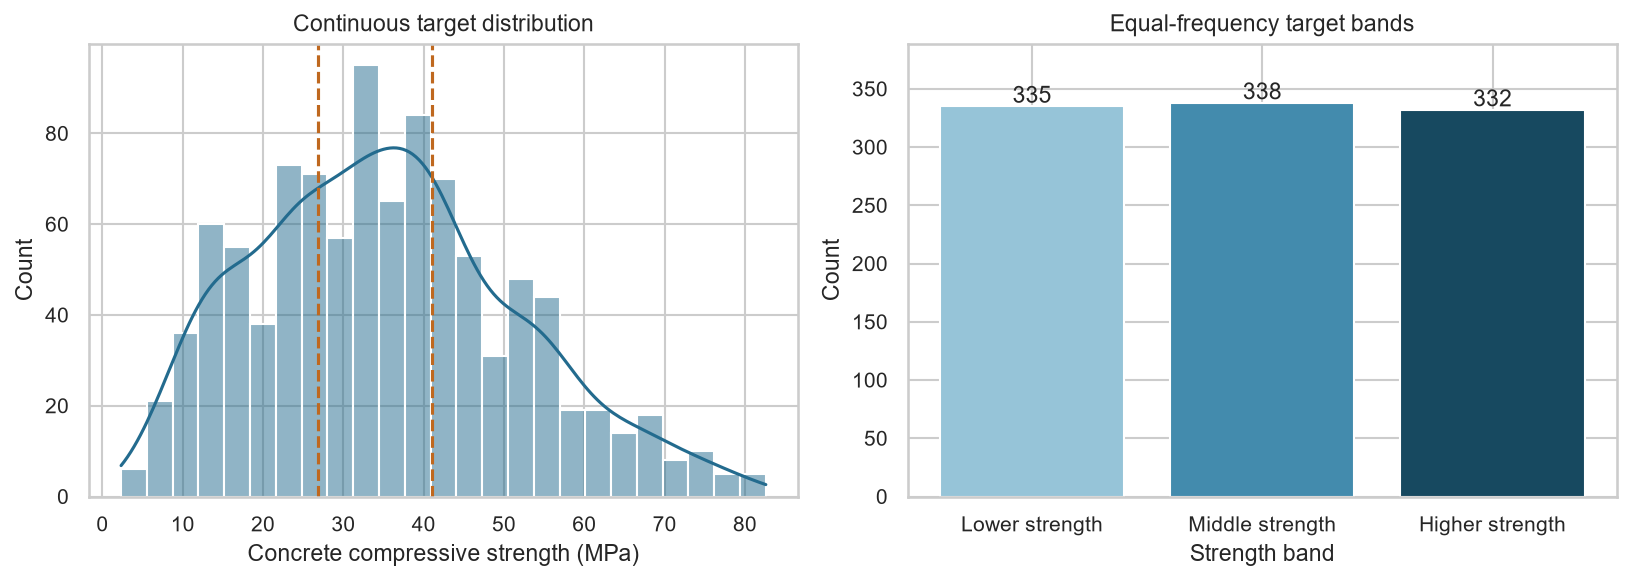

In [7]:
class_labels = ['Lower strength', 'Middle strength', 'Higher strength']
clean['strength_class'], class_edges = pd.qcut(
    clean[TARGET], q=3, labels=class_labels, retbins=True)
class_counts = clean['strength_class'].value_counts(sort=False)
class_table = pd.DataFrame({
    'count': class_counts,
    'percent': class_counts / len(clean) * 100
})
print('Continuous target summary (MPa):')
print(clean[TARGET].describe().round(3).to_string())
print('Target skewness:', round(clean[TARGET].skew(), 4))
print('Full-precision class edges:', [float(e) for e in class_edges])
print(class_table.round(3).to_string())
print('Any class above 80%:', bool((class_table['percent'] > 80).any()))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(clean[TARGET], bins=25, kde=True, ax=axes[0], color='#236b8e')
axes[0].set(title='Continuous target distribution',
            xlabel='Concrete compressive strength (MPa)', ylabel='Count')
axes[0].axvline(class_edges[1], color='#bf681f', linestyle='--')
axes[0].axvline(class_edges[2], color='#bf681f', linestyle='--')
axes[1].bar(class_labels, class_counts, color=['#96c4d8', '#438bad', '#174960'])
axes[1].set(title='Equal-frequency target bands', xlabel='Strength band', ylabel='Count')
for i, n in enumerate(class_counts):
    axes[1].text(i, n + 3, str(n), ha='center')
axes[1].set_ylim(0, class_counts.max() * 1.15)
fig.tight_layout()
fig.savefig(OUTPUT / '03_target.png', dpi=180)
plt.show()

The cleaned target spans 2.33-82.60 MPa, with mean 35.250,
median 33.800 and standard deviation 16.285 MPa.
Skewness is 0.396, indicating mild right asymmetry rather than a demonstrated
normal distribution. The lower band includes [2.33, 26.823333], the middle band includes
(26.823333, 41.050000], and the higher band includes (41.050000, 82.60] MPa.
Counts are 335, 338 and 332; ties at
boundaries account for slight differences. No class exceeds 80%.

Full-dataset quantiles are used only to describe this portfolio dataset. For future supervised
evaluation, learn boundaries from the training data alone and apply the fixed boundaries to
validation/test responses, or define external thresholds before splitting. The continuous target
and derived class must both be excluded from predictors. Correlations below use the original
continuous target; arbitrary numeric encoding of class names would be inappropriate.

## 3 Key findings from univariate analysis
### Task 4 Individual predictor distributions
All eight predictors are examined, exceeding the minimum of six numerical predictor plots.
The summary table reports count, mean, standard deviation, quartiles, minimum, maximum,
skewness, distinct-value count and zero percentage. Histograms reveal structure that means alone
can hide. Distribution descriptions are observational; no formal normality test is claimed.

Predictors: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']
                     count     mean      std    min
cement              1005.0  278.631  104.344  102.0
blast_furnace_slag  1005.0   72.043   86.171    0.0
fly_ash             1005.0   55.536   64.208    0.0
water               1005.0  182.075   21.339  121.8
superplasticizer    1005.0    6.033    5.920    0.0
coarse_aggregate    1005.0  974.377   77.580  801.0
fine_aggregate      1005.0  772.688   80.340  594.0
age                 1005.0   45.857   63.735    1.0

                      25%    50%     75%     max
cement              190.7  265.0   349.0   540.0
blast_furnace_slag    0.0   20.0   142.5   359.4
fly_ash               0.0    0.0   118.3   200.1
water               166.6  185.7   192.9   247.0
superplasticizer      0.0    6.1    10.0    32.2
coarse_aggregate    932.0  968.0  1031.0  1145.0
fine_aggregate      724.3  780.0   822.2   992.6
age      

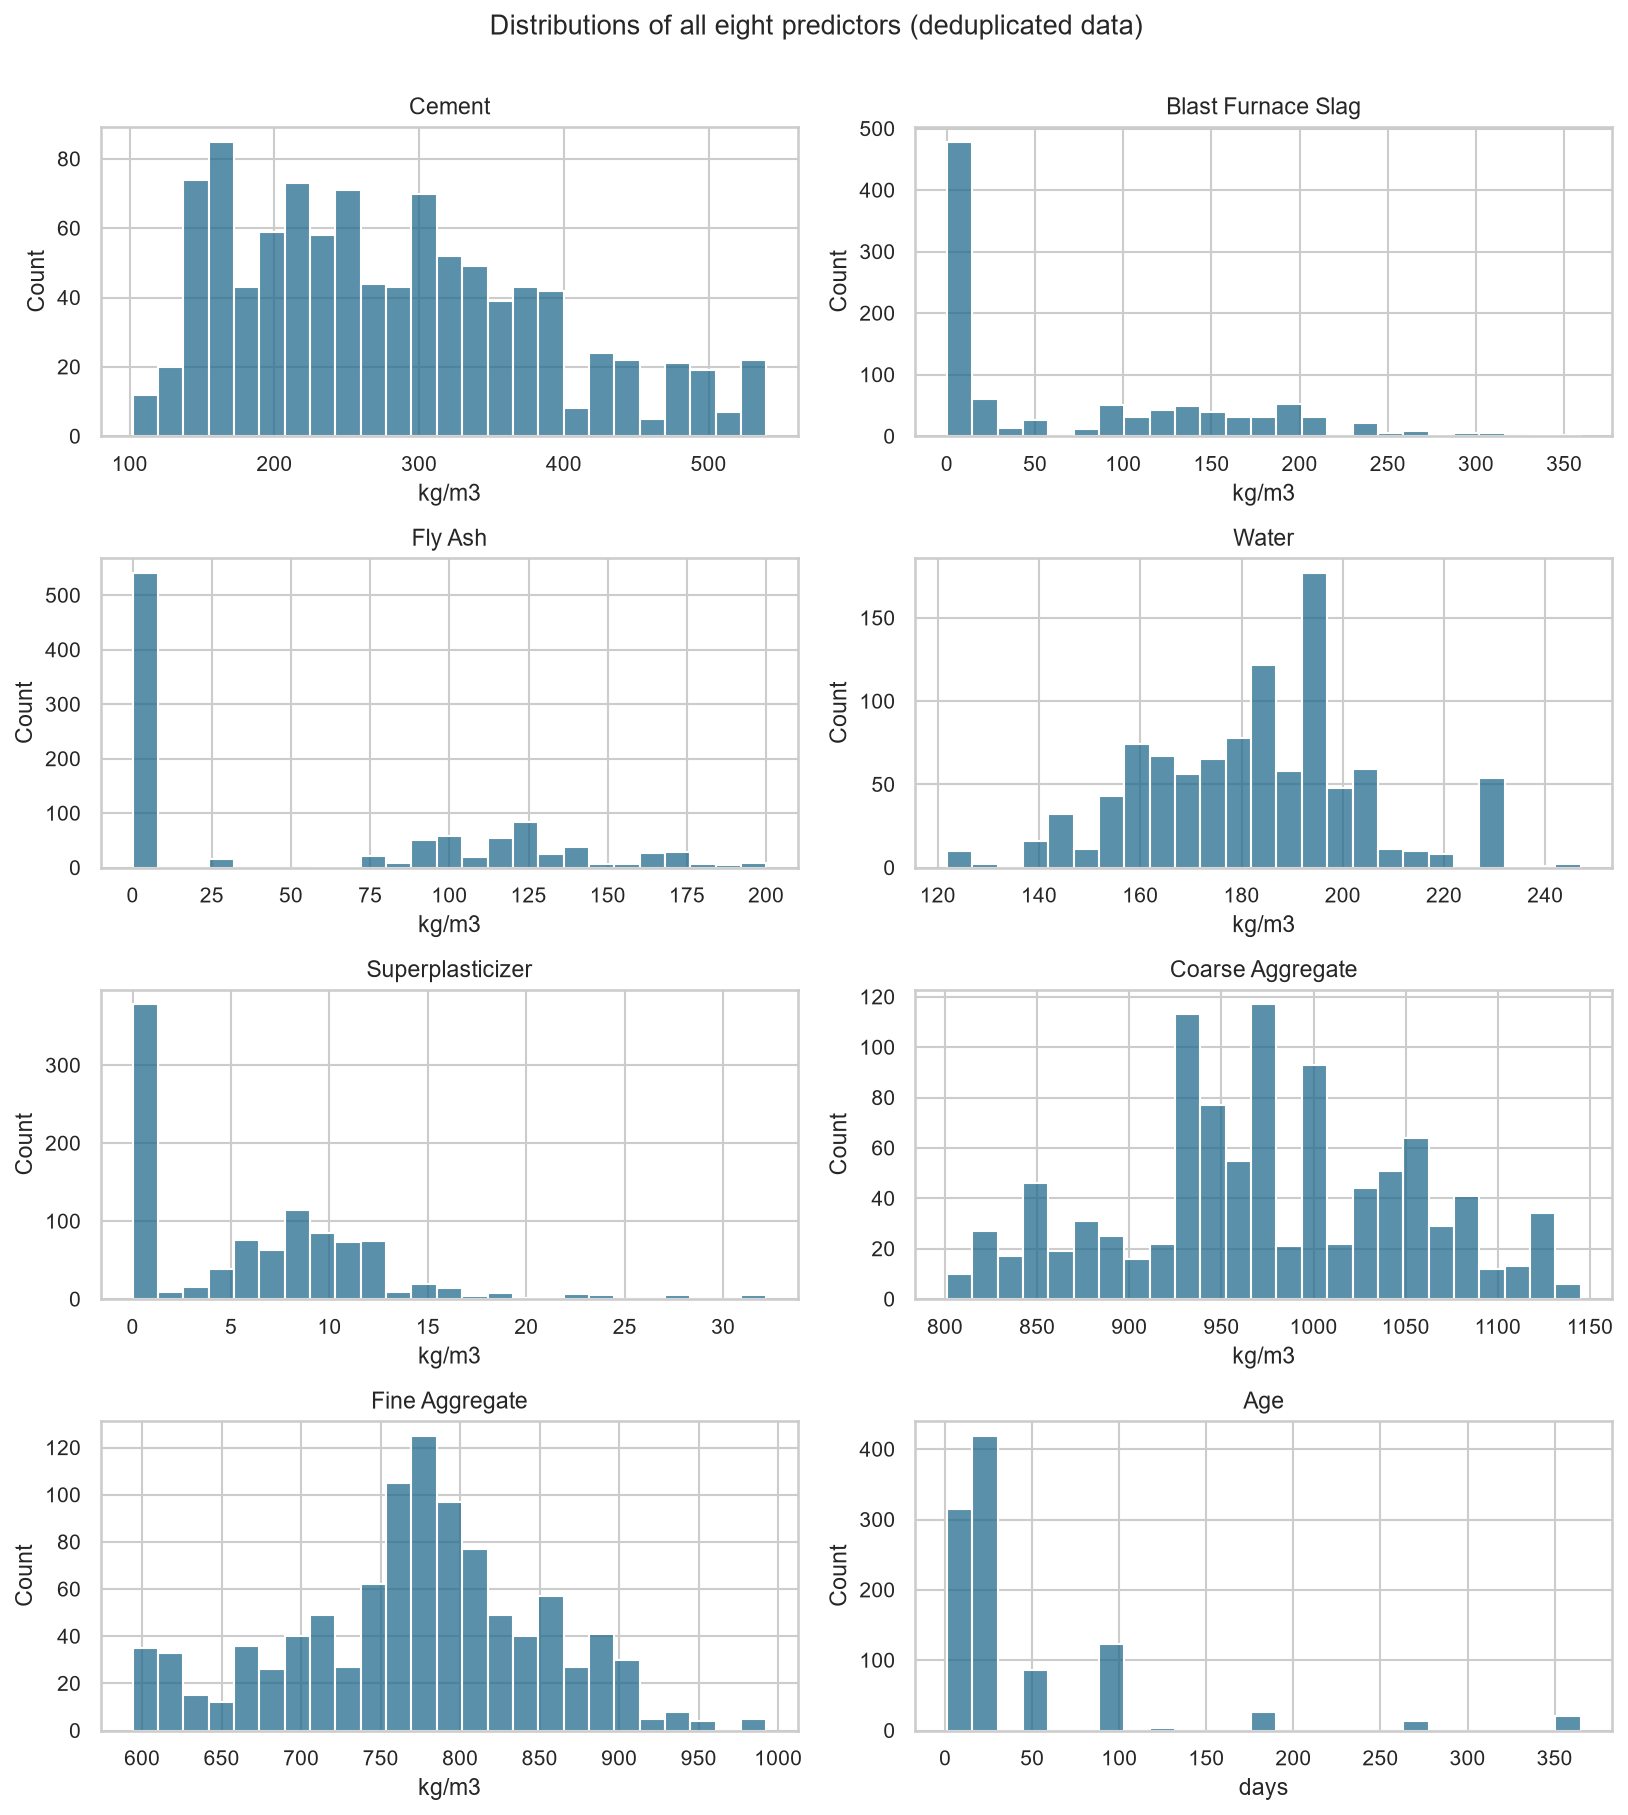

In [8]:
print('Predictors:', PREDICTORS)
predictor_summary = clean[PREDICTORS].describe().T
predictor_summary['skewness'] = clean[PREDICTORS].skew()
predictor_summary['unique_values'] = clean[PREDICTORS].nunique()
predictor_summary['zero_percent'] = clean[PREDICTORS].eq(0).mean() * 100
print_table(predictor_summary.round(3))
fig, axes = plt.subplots(4, 2, figsize=(11, 12))
for ax, col in zip(axes.flat, PREDICTORS):
    sns.histplot(clean[col], bins=25, color='#236b8e', ax=ax)
    ax.set(title=LABELS[col], xlabel=UNITS[col], ylabel='Count')
fig.suptitle('Distributions of all eight predictors (deduplicated data)', y=1.005)
fig.tight_layout()
fig.savefig(OUTPUT / '04_predictors.png', dpi=180, bbox_inches='tight')
plt.show()

Cement is moderately right-skewed (skewness 0.565). Slag and fly ash
have large masses at zero: 46.77% and
53.83% of samples omit them. Treating these zeros as missing
would invent ingredients. Superplasticizer is also zero in
37.61% of rows and has a right tail.

Water has near-zero skewness (0.034) but repeated recipe values and a
non-smooth distribution, so symmetry alone is insufficient to label it normally distributed.
Coarse aggregate is roughly symmetric (-0.065); fine aggregate has
mild left asymmetry (-0.252). Age is strongly right-skewed
(3.254) and concentrated at scheduled test days. The 28-day group has 419
observations, or 41.69% of the cleaned sample. Rare long ages should be preserved and assessed
separately during future evaluation. A log-age transformation is a candidate, not a requirement
already applied to these plots.

## 4 Key findings from multivariate analysis
### Task 5 Correlations and predictor relationships
Pearson coefficients rank linear associations by absolute magnitude and retain their signs.
The heatmap includes the eight original predictors and the continuous strength target.
Spearman correlations provide a rank-based sensitivity check for skewness and nonlinear
monotonic patterns. A pairplot and age-group summaries explore relationships beyond coefficients.

                    Pearson_r  Spearman_rho
cement                 0.4883        0.4614
superplasticizer       0.3442        0.3218
age                    0.3374        0.6054
water                 -0.2696       -0.2843
fine_aggregate        -0.1864       -0.1933
coarse_aggregate      -0.1447       -0.1629
blast_furnace_slag     0.1034        0.1403
fly_ash               -0.0806       -0.0563
Top three by absolute Pearson correlation:
                  Pearson_r  Spearman_rho
cement               0.4883        0.4614
superplasticizer     0.3442        0.3218
age                  0.3374        0.6054


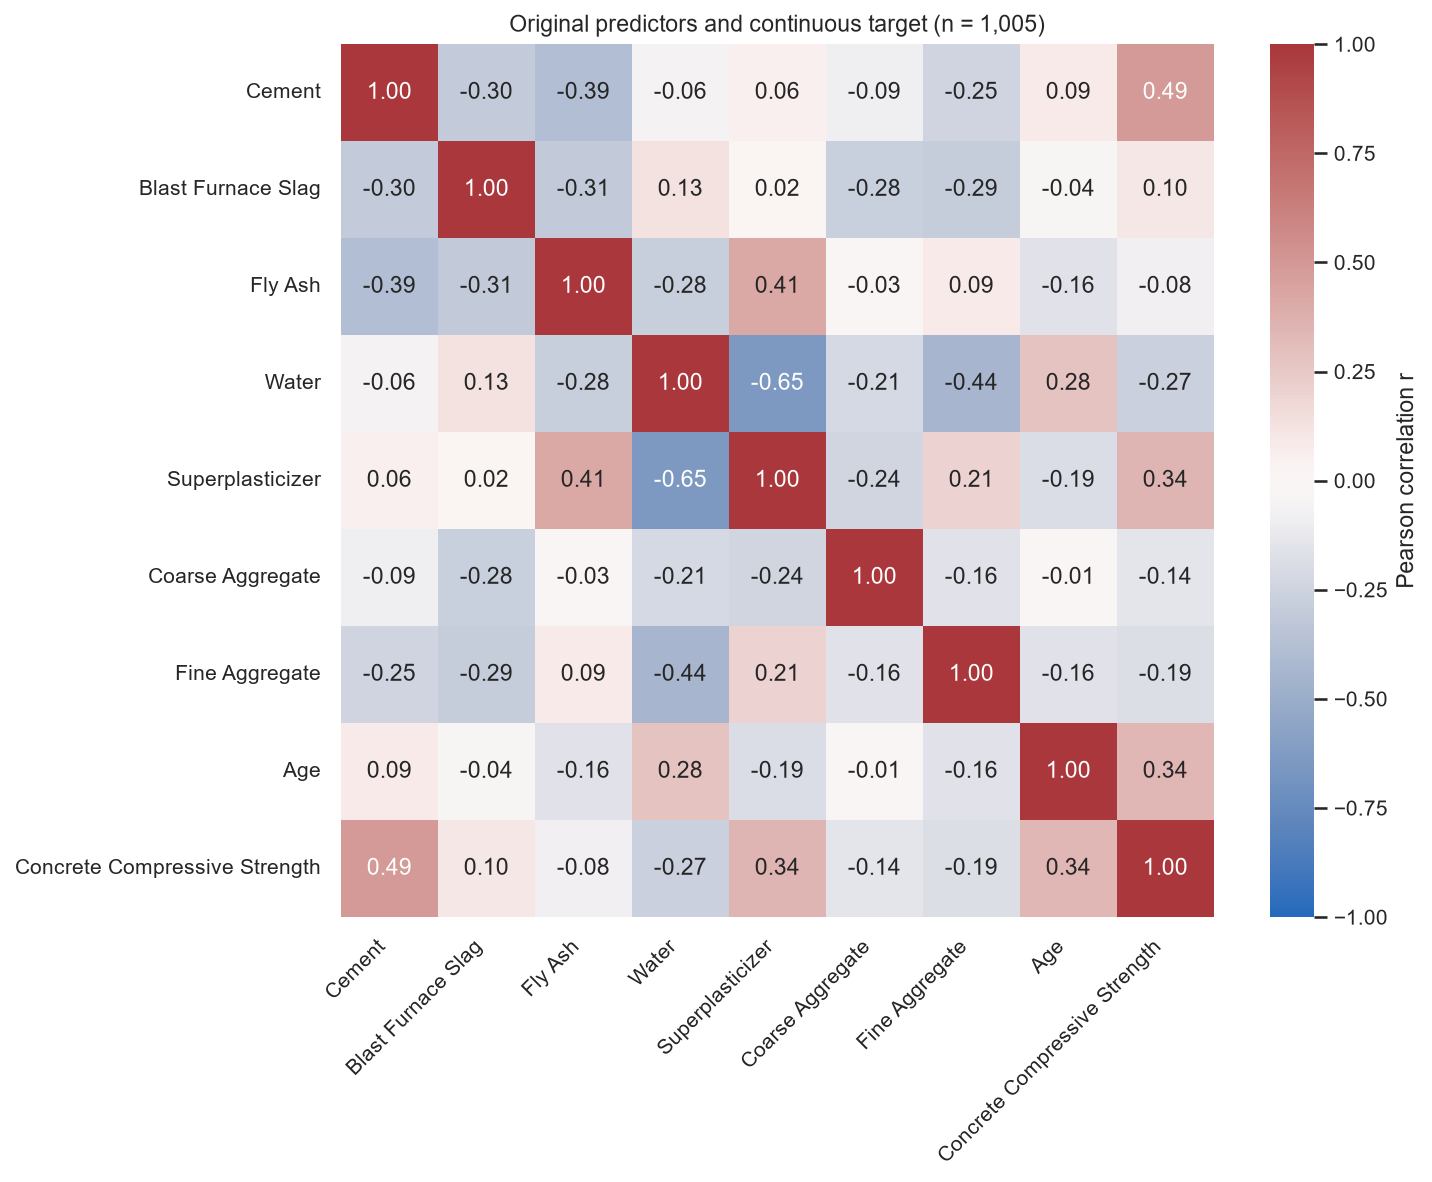

In [9]:
analysis_columns = PREDICTORS + [TARGET]
pearson = clean[analysis_columns].corr(method='pearson')
spearman = clean[analysis_columns].corr(method='spearman')
target_correlations = pd.DataFrame({
    'Pearson_r': pearson[TARGET].drop(TARGET),
    'Spearman_rho': spearman[TARGET].drop(TARGET)
}).sort_values('Pearson_r', key=lambda s: s.abs(), ascending=False)
print(target_correlations.round(4).to_string())
print('Top three by absolute Pearson correlation:')
print(target_correlations.head(3).round(4).to_string())
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(pearson, annot=True, fmt='.2f', cmap='vlag', center=0,
            vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'label': 'Pearson correlation r'})
ax.set_xticklabels([LABELS[c] for c in analysis_columns], rotation=45, ha='right')
ax.set_yticklabels([LABELS[c] for c in analysis_columns], rotation=0)
ax.set_title('Original predictors and continuous target (n = 1,005)')
fig.tight_layout()
fig.savefig(OUTPUT / '05_correlation.png', dpi=180)
plt.show()

In [10]:
# Review high pairwise associations, then assess joint collinearity with VIF.
pairs = []
for i, a in enumerate(PREDICTORS):
    for b in PREDICTORS[i + 1:]:
        pairs.append((a, b, pearson.loc[a, b]))
pair_correlations = pd.DataFrame(pairs, columns=['predictor_1', 'predictor_2', 'r'])
pair_correlations = pair_correlations.sort_values('r', key=lambda s: s.abs(), ascending=False)
print('Strongest predictor pairs:')
print(pair_correlations.head(5).round(4).to_string(index=False))
print('Pairs with |r| >= 0.80:', int(pair_correlations['r'].abs().ge(.8).sum()))
X = clean[PREDICTORS].to_numpy(dtype=float)
vif_rows = []
for j, col in enumerate(PREDICTORS):
    others = np.delete(X, j, axis=1)
    design = np.column_stack([np.ones(len(X)), others])
    fitted = design @ np.linalg.lstsq(design, X[:, j], rcond=None)[0]
    residual_ss = np.sum((X[:, j] - fitted) ** 2)
    total_ss = np.sum((X[:, j] - X[:, j].mean()) ** 2)
    vif_rows.append((col, total_ss / residual_ss))
vif = pd.DataFrame(vif_rows, columns=['predictor', 'VIF'])
print('VIF from auxiliary regressions with an intercept:')
print(vif.sort_values('VIF', ascending=False).round(3).to_string(index=False))
print('VIF is a diagnostic; no strength-prediction model is trained.')

Strongest predictor pairs:
       predictor_1      predictor_2       r
             water superplasticizer -0.6469
             water   fine_aggregate -0.4449
           fly_ash superplasticizer  0.4142
            cement          fly_ash -0.3856
blast_furnace_slag          fly_ash -0.3124
Pairs with |r| >= 0.80: 0
VIF from auxiliary regressions with an intercept:
         predictor   VIF
            cement 7.449
blast_furnace_slag 7.263
    fine_aggregate 6.972
             water 6.838
           fly_ash 6.085
  coarse_aggregate 4.956
  superplasticizer 2.867
               age 1.120
VIF is a diagnostic; no strength-prediction model is trained.


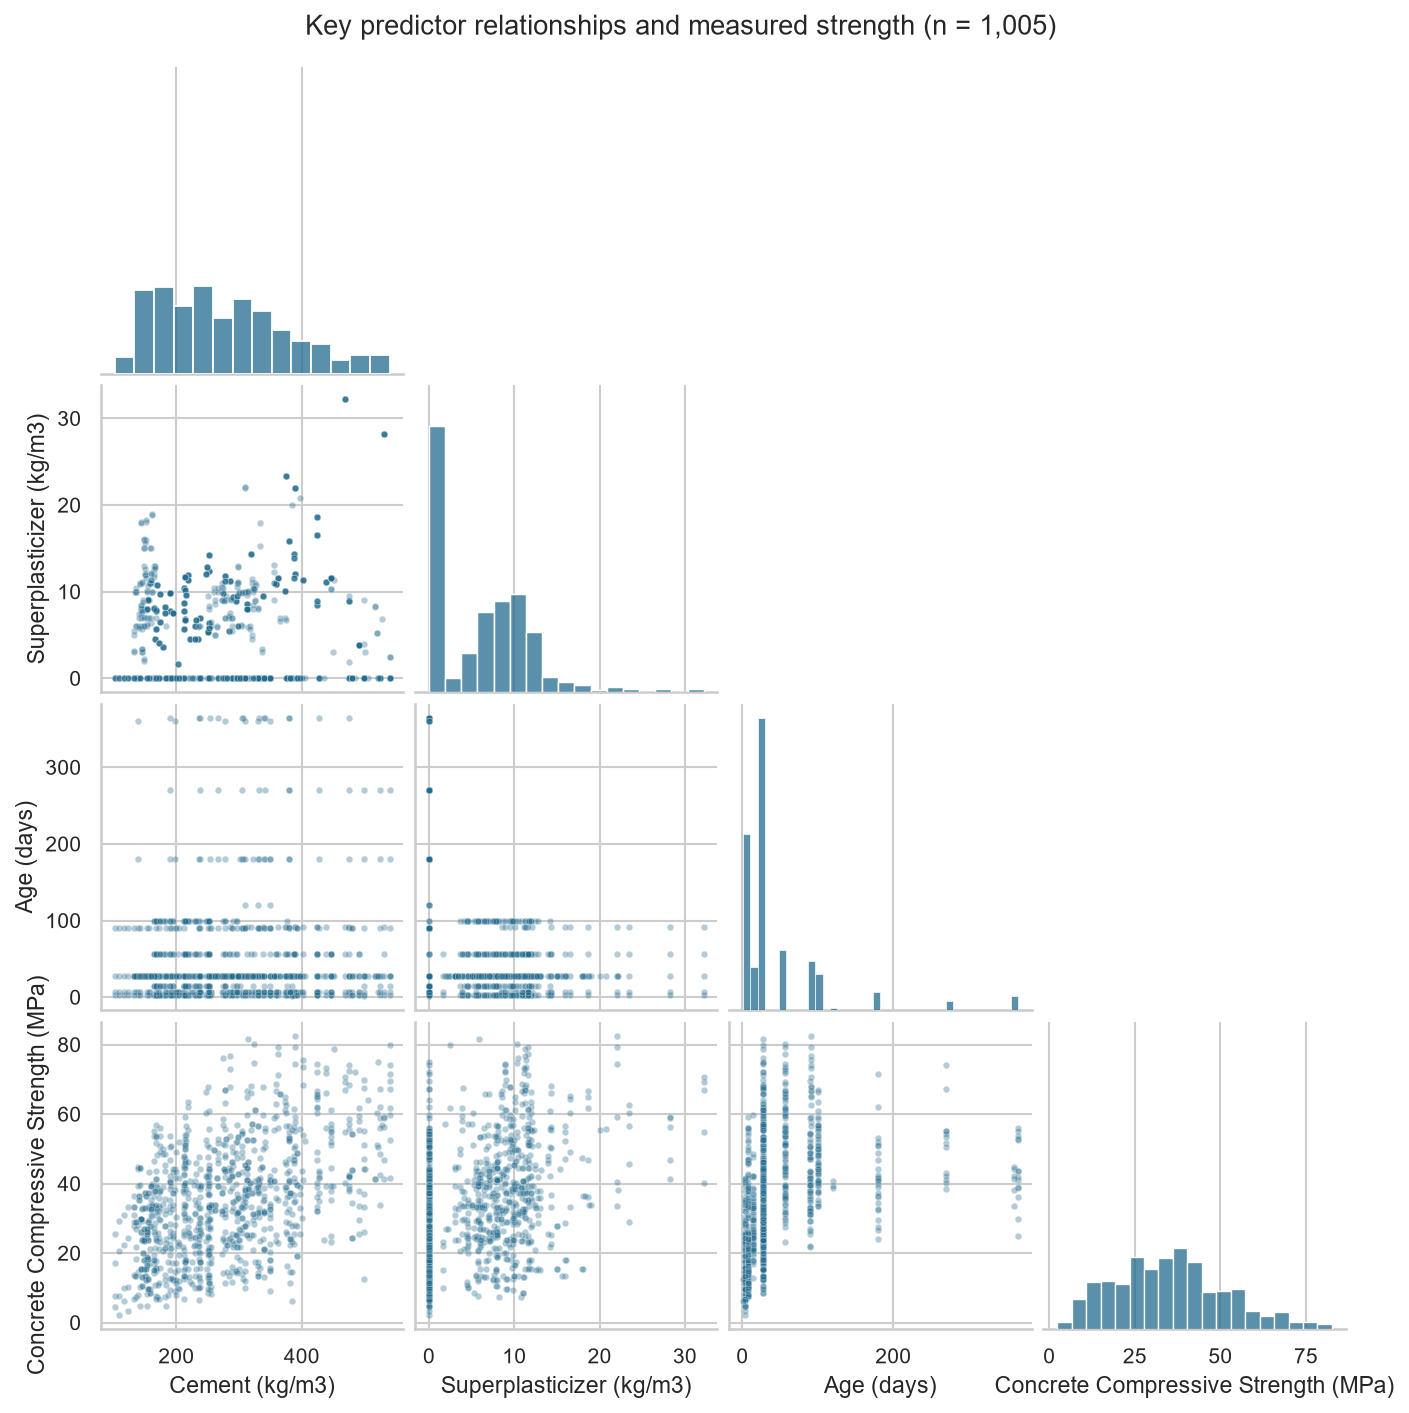

In [11]:
# All cleaned rows are included; plot labels include measurement units.
key = ['cement', 'superplasticizer', 'age', TARGET]
plot_data = clean[key].rename(columns={
    c: LABELS[c] + ' (' + UNITS[c] + ')' for c in key
})
grid = sns.pairplot(plot_data, corner=True, diag_kind='hist', height=2.3,
                    plot_kws={'s': 10, 'alpha': .35, 'color': '#236b8e'},
                    diag_kws={'color': '#236b8e'})
grid.fig.suptitle('Key predictor relationships and measured strength (n = 1,005)', y=1.02)
grid.fig.savefig(OUTPUT / '06_pairplot.png', dpi=180, bbox_inches='tight')
plt.show()

Strength by observed age (MPa):
     count    mean  median
age                       
1        2   9.455   9.455
3      129  18.378  15.520
7      122  25.182  21.170
14      62  28.751  26.540
28     419  36.430  33.730
56      86  50.715  51.150
90      54  40.480  39.680
91      17  68.676  67.800
100     52  47.669  46.985
120      3  39.647  39.380
180     26  41.730  40.905
270     13  51.272  51.730
360      6  40.697  41.685
365     14  43.558  42.815


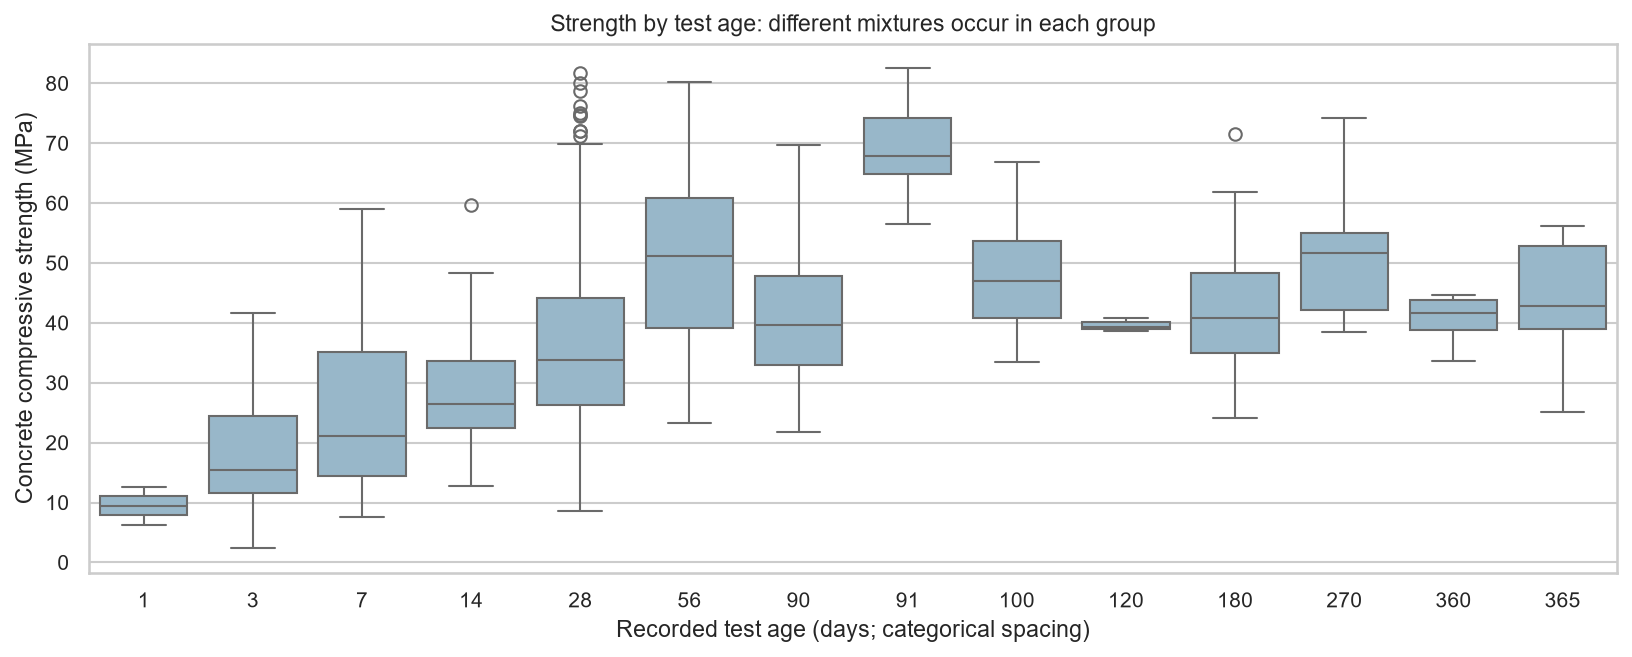

In [12]:
age_summary = clean.groupby('age')[TARGET].agg(['count', 'mean', 'median'])
print('Strength by observed age (MPa):')
print(age_summary.round(3).to_string())
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=clean, x='age', y=TARGET, color='#90b9d1', ax=ax)
ax.set(title='Strength by test age: different mixtures occur in each group',
       xlabel='Recorded test age (days; categorical spacing)',
       ylabel='Concrete compressive strength (MPa)')
fig.tight_layout()
fig.savefig(OUTPUT / '07_age_strength.png', dpi=180)
plt.show()

The three strongest original predictors by absolute Pearson correlation are cement
(r = 0.4883), superplasticizer (r = 0.3442) and age
(r = 0.3374). These are marginal associations, not independent effects or a model
performance estimate. Age has Spearman rho = 0.6054, substantially larger than Pearson
r = 0.3374, consistent with an important monotonic component obscured by uneven ages and
mix differences. The pairplot shows vertical age bands and substantial variation at the same
age; a straight line alone is unlikely to describe the full process.

The strongest predictor-predictor association is water versus superplasticizer
(r = -0.6469). No pair reaches the descriptive |r| >= 0.80 screening threshold, but pairwise
screening cannot rule out joint multicollinearity. VIF is 7.449 for cement, 7.263 for slag,
6.972 for fine aggregate, 6.838 for water and 6.085 for fly ash, indicating appreciable joint
redundancy. The remaining values are 4.956 for coarse aggregate, 2.867 for superplasticizer
and 1.120 for age. VIF above 5 is treated as a review flag, not a universal deletion rule.
The constant-volume mixture formulation can constrain
the ingredient quantities; correlations should therefore be interpreted with recipe structure
in mind. Regularisation or carefully selected features may be preferable to interpreting
unregularised coefficients independently.

Age-group means are not strictly increasing: the 56-day group averages 50.715 MPa whereas
the 90-day group averages 40.480 MPa. This does not show that concrete weakens between
56 and 90 days, because the groups contain different mixtures. The 1-day and 120-day groups
have only two and three observations; apparent differences there are especially uncertain.

## 5 Initial insights for modelling
This section proposes future work; no predictive model is fitted or evaluated.

Keep all eight original predictors available initially. Cement, age and superplasticizer deserve
attention, while water has a negative marginal association with strength. A weak marginal
coefficient for fly ash or slag does not justify deleting it: substitution effects and interactions
with age can hide predictive information.

For regression, compare a mean baseline, ridge regression and tree-based models such as random
forest or gradient boosting. Ridge can manage correlated ingredients; trees can capture nonlinear
age and composition interactions. Use MAE and RMSE in MPa and examine errors by age and
strength range. For the three-class alternative, compare a majority baseline, regularised
multinomial logistic regression and a tree classifier using macro-F1 and a confusion matrix.
An ordinal approach could exploit band order. Performance remains unknown until evaluation.

Scale numerical inputs inside a training-only pipeline for ridge/logistic models; trees normally
do not require scaling. No categorical input encoding is needed. Keep strength_class solely as
an outcome and exclude continuous strength from class predictors. Consider log1p(age), binder
content and water-to-binder ratio. Derived quantities must be assessed for added redundancy.
Use group-aware splits by original mix composition, so repeated recipes across ages are not
shared across folds. Batch-level grouping is preferable if batch IDs become available.
Any imputation, scaling, selection, outlier policy and quantile thresholds must be fitted using
training data alone. Do not oversample before splitting; these EDA classes are already balanced.

## 6 Engineering interpretation
### Task 6 Physical meaning and missing information
Greater cement content is positively associated with strength in this dataset. A plausible
interpretation is greater binder availability, but water and ingredient substitution also change;
the coefficient is not an instruction to add cement while holding all else fixed.

The positive age association is consistent with continued hydration and strength development
under appropriate curing. The negative water association and positive superplasticizer
association are consistent with achieving workable mixtures at lower water demand. The American
Cement Association describes water-cement ratio and curing as important strength factors [3, 4].
This is an engineering interpretation rather than a causal estimate from this table.

To explore composition more directly, an additional water-to-binder ratio is computed as water
divided by cement plus slag plus fly ash. This treats all three as nominal binder mass for
exploration and does not imply identical reactivity. It is distinct from water-to-cement ratio.

Water-to-binder ratio summary:
count    1005.0000
mean        0.4731
std         0.1255
min         0.2351
25%         0.3895
50%         0.4800
75%         0.5613
max         0.9000
Pearson r with strength: -0.6108


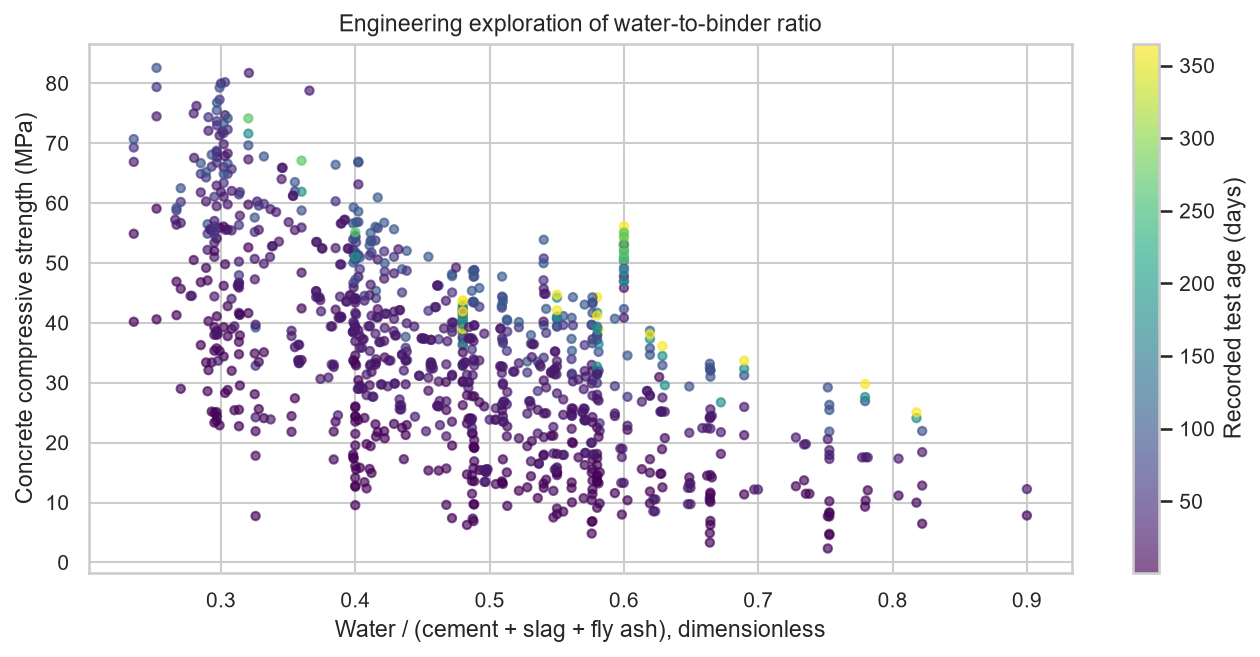

In [13]:
# Derived feature for an additional engineering check, not the original top-three ranking.
binder = clean['cement'] + clean['blast_furnace_slag'] + clean['fly_ash']
if (binder <= 0).any():
    raise ValueError('Binder must be positive before computing a ratio.')
water_binder_ratio = clean['water'] / binder
ratio_r = water_binder_ratio.corr(clean[TARGET])
print('Water-to-binder ratio summary:')
print(water_binder_ratio.describe().round(4).to_string())
print('Pearson r with strength:', round(ratio_r, 4))
fig, ax = plt.subplots(figsize=(9, 4.5))
points = ax.scatter(water_binder_ratio, clean[TARGET], c=clean['age'],
                    cmap='viridis', s=16, alpha=.65)
fig.colorbar(points, ax=ax, label='Recorded test age (days)')
ax.set(title='Engineering exploration of water-to-binder ratio',
       xlabel='Water / (cement + slag + fly ash), dimensionless',
       ylabel='Concrete compressive strength (MPa)')
fig.tight_layout()
fig.savefig(OUTPUT / '08_water_binder.png', dpi=180)
plt.show()

The water-to-binder ratio has Pearson r = -0.6108 with strength, larger in
absolute magnitude than any original individual predictor. This motivates a feature candidate,
but does not establish that it improves held-out prediction. The scatterplot is coloured by age
to show that mixtures at similar ratios can still differ in test maturity.

An unexpected marginal finding is the small negative fly-ash coefficient (r = -0.0806).
It may reflect cement replacement, different test ages and interacting ingredients; it does
not demonstrate that fly ash always reduces strength. Missing variables that could help explain
residual variation include curing temperature/moisture, cement type, supplementary-material
chemistry, aggregate grading, air content, specimen geometry, compaction and laboratory/batch
identifiers. A nonlinear regression model is a reasonable candidate because these process
relationships involve ratios and interactions; that choice requires validation.

## 7 Challenges encountered
### Task 7 Data preparation decisions
The main observed challenges were a trailing space in a column header, ambiguity about exact
duplicates, valid zero ingredient quantities and heavy age skewness. Header normalisation fixes
the first issue. Raw data is retained; exact duplicate removal is accompanied by a sensitivity
check, and repeated inputs with different strengths remain. No missing values are fabricated.
IQR flags are documented without automatic deletion because long-age tests and unusual recipes
can be legitimate. All outputs distinguish 1,030 raw rows from 1,005 analysis rows.

Another challenge is separating an engineering regression outcome from the required classification
bands. Quantiles provide balance but replace physical units with relative ranks. Continuous
strength is therefore preserved for interpretation, and target-derived information is kept out of
features. Pairwise correlations alone miss joint ingredient redundancy, so VIF is added as a
diagnostic. These are documented project decisions; no personal experience is invented.

## 8 Responsible AI reflection
### Task 8 Reliability, bias and ethical concerns
Poor quality can reduce reliability in several ways. A unit error would change ingredient
relationships, unknown duplicated experiments could overweight recipes, and deleting all old-age
outliers would remove valid behaviour. Different measured outcomes for the same recorded inputs
show that the inputs do not fully specify the strength outcome. Data validation and provenance
are therefore as important as the algorithm.

Sampling coverage is a bias concern. The data represents laboratory mixes and uneven test ages,
not a random sample of current Vietnamese construction. There is no adequate metadata to prove
coverage of local cement, climate, curing practices or laboratory conditions. Assess future errors
by age and mix range, seek independent local data and state the supported prediction domain.
Protected-attribute fairness tests are not applicable to the recorded material variables, but
unequal coverage of producers or local materials could still disadvantage users.

Overestimating strength could lead to unsafe mix screening decisions; underestimating it could
increase material use and cost. A future model should communicate uncertainty and remain subject
to qualified engineering review and laboratory verification. Strength alone does not quantify
carbon impact or cost; these objectives require additional evidence. This CSV contains no visible
personal identifiers. Preserve attribution and avoid presenting an AI draft as independently
authored work. This reflection requires the student's review before submission.

## 9 Next steps and summary
### Task 9 Structured report and future investigation
The raw dataset is complete and numerical, but contains exact repetitions. The chosen analysis
retains 1,005 distinct full observations and keeps physically plausible IQR outliers. Eight
predictor distributions, target bands, a correlation heatmap, pairplot, age comparison and an
engineering ratio exploration are provided. Cement, superplasticizer and age lead the original
Pearson ranking, while age shows a stronger rank association. These findings support testing
nonlinear and regularised methods, not claiming model accuracy.

Next, obtain experiment/batch provenance, compare retained-versus-removed duplicate policies,
define the operational target and evaluation split, test group-aware pipelines and collect curing
and material metadata. Compare raw predictors against carefully chosen ratio features, quantify
uncertainty and verify transfer to independent laboratories or local materials. For a classification
task, decide whether quantile bands or pre-agreed engineering boundaries serve the intended use.
The submission repository is https://github.com/odmiefnf/COS40007. Canvas submission has not been performed.

## 10 GenAI declaration and evidence
The declaration at the beginning records the actual scope of assistance. The delivered notebook
contains the code and computed outputs; tools/GENAI_EVIDENCE.md records prompts, scope and
verification actions. Do not substitute the assignment's ownership statement unless it becomes
true after student verification and revision. Check the tutor's permission for broader AI use.

## References
[1] Darlington, A. (elikplim). Concrete Compressive Strength Data Set. Kaggle mirror.
https://www.kaggle.com/datasets/elikplim/concrete-compressive-strength-data-set

[2] Yeh, I. (1998). Concrete Compressive Strength [Dataset]. UCI Machine Learning Repository.
https://doi.org/10.24432/C5PK67 . Original collection attribution retained.
Kaggle lists the mirror's licence as unknown; UCI identifies its original dataset as CC BY 4.0.
These notices are recorded separately rather than assigning the UCI licence to the mirror.

[3] American Cement Association. Applications of Cement.
https://www.cement.org/cement-concrete/applications-of-cement/

[4] American Cement Association. Cement and Concrete FAQ.
https://www.cement.org/cement-concrete/cement-concrete-faq/

Sources accessed 2 October 2026. Dataset description and units use [1, 2]; [3, 4] support the
qualitative engineering interpretation. All statistics and plots are calculated from the CSV.

In [14]:
# Export a prepared table and diagnostics; preserve the original CSV.
clean.to_csv(OUTPUT / 'concrete_prepared.csv', index=False)
missing.to_csv(OUTPUT / 'missing_values.csv')
outlier_table.to_csv(OUTPUT / 'outlier_assessment.csv')
predictor_summary.to_csv(OUTPUT / 'predictor_summary.csv')
target_correlations.to_csv(OUTPUT / 'target_correlations.csv')
vif.to_csv(OUTPUT / 'vif.csv', index=False)
class_table.to_csv(OUTPUT / 'class_distribution.csv')
print('Prepared table:', clean.shape)
print('Original predictors:', len(PREDICTORS))
print('Missing input/target cells:', int(clean[PREDICTORS + [TARGET]].isna().sum().sum()))
print('Exact duplicates after cleaning:', int(clean.duplicated(subset=PREDICTORS + [TARGET]).sum()))
print('Class count total:', int(class_counts.sum()))
print('Class boundaries strictly increasing:', bool(np.all(np.diff(class_edges) > 0)))
print('All original predictors numeric:', all(pd.api.types.is_numeric_dtype(clean[c]) for c in PREDICTORS))
print('Prepared data and evidence tables saved to output/.')

Prepared table: (1005, 10)
Original predictors: 8
Missing input/target cells: 0
Exact duplicates after cleaning: 0
Class count total: 1005
Class boundaries strictly increasing: True
All original predictors numeric: True
Prepared data and evidence tables saved to output/.
